\tableofcontents

\newpage


# Abstract

This study investigates the extent to which human choice patterns can be replicated in synthetic experiments utilizing Large Language Models. Two specific cognitive patterns are selected for simulation: **intertemporal behavior** (e.g., "Do you prefer receiving \$140 next year over receiving \$100 now?"), and risk-aversion/risk-seeking behavior (e.g., "Do you prefer a 90% chance of \$5,000 over \$1,000 for sure?"). Both patterns are assessed across individuals with varying levels of cognitive intelligence, hereafter referred to as IQ.

To evaluate the accuracy of LLM responses, a comparison is made with human survey data, specifically utilizing the framework established by [Frederick, Shane. (2005)](https://pubs.aeaweb.org/doi/pdf/10.1257/089533005775196732?_ref=finder&combine=Can%20I%20send%20my%20application%20file%20without%20a%20GMAT%2C%20GRE%20or%20TOEFL%20test%3F&mode=list_insead_stories&page=7). The simulation proceeds through the following steps:

1. An **artificial population** is generated based on demographic characteristics such as cognitive intelligence, location, age, and personality, as described in the paper.
2. A survey measuring **intertemporal behavior** is administered to this synthetic population, and the results are compared with those of a human survey to assess the alignment of key behavioral patterns.
3. A similar process is followed for evaluating **risk-taking behavior**, where the LLM's responses are compared with human responses and visualized graphically.
4. Finally, a **robustness test** is conducted to examine **the framing effect** by assessing whether the inclusion of additional questions influences the LLM’s responses. The results indicate that such framing does not affect LLM behavior, whereas human responses appear susceptible to framing, warranting further investigation into this divergence.







# Initiation
## Install `edsl`

In [1]:
!pip install edsl > /dev/null 2>&1 #install silently

The session should be reset after installing `edsl`

## Import required libraries

In [2]:
from edsl import AgentList, Agent, Coop, Notebook, Survey
from edsl import QuestionYesNo, QuestionMultipleChoice, QuestionLinearScale
import random
import os

## Set API key

In [3]:
# The Expected Parrot key is read from the environment and is never stored in the notebook.
# Set it before starting Jupyter (export EXPECTED_PARROT_API_KEY=...) or in a local .env file,
# which edsl loads automatically and which is ignored by git.
assert os.environ.get('EXPECTED_PARROT_API_KEY'), 'Set the EXPECTED_PARROT_API_KEY environment variable first.'

# Part 1) Defining Agents' Characteristics for Synthetic Society Generation

In this section, we define the characteristics of agents based on the framework presented in the paper (Table 1). Summary statistics are provided regarding the IQ levels, locations, and personas of the individuals who participated in the survey. Using this information, I generate a synthetic sample society. To reduce computational complexity, the population in this simulation is limited to 10% of the original dataset. Agents are categorized according to Table 1, with the CRT test being simplified into a binary criterion: individuals scoring 2 or higher on the CRT are classified as having a "High IQ," indicating greater capacity for correct answers. The number of observations is reduced by a factor of 10 as mentioed, and corresponding locations, conditions, and personas are assigned to the LLM in order to create the relevant agents.



In [4]:
# Define the location, IQ percentage, and number of agents for each location
locations_data = [
    ("Massachusetts Institute of Technology", 78, 6),
    ("Princeton University", 54, 12),
    ("Boston fireworks display", 52, 19),
    ("Carnegie Mellon University", 50, 75),
    ("Harvard University", 44, 5),
    ("University of Michigan: Ann Arbor", 37, 127),
    ("Web-based studies", 39, 52),
    ("Bowling Green University", 25, 5),
    ("University of Michigan: Dearborn", 25, 15),
    ("Michigan State University", 22, 12),
    ("University of Toledo", 15, 14)
]

# Define persona information for the locations where available
personas = {
    "Boston fireworks display": "Respondents in this study were people picnicking along the banks of the Charles River prior to the July 4th fireworks display. Their ages ranged from 15 to 63, with a mean of 24. Many of the younger participants were presumably students at a college in the Boston or Cambridge area. Most completed the survey in small groups of friends or family. Although they were requested not to discuss it until everyone in their group had completed it, some may have. (This, presumably, would elevate the CRT scores relative to most of the other studies in which participation was more closely supervised.)",

    "Harvard University": "The participants in this study were all members of a student choir group, which was predominately female. Unlike the other locations in which the numbers of men and women were comparable, 42 of 51 participants in this study were women.",

    "Web-based studies": "These were participants in two online studies, consisting of both college students and others whose e-mail addresses were obtained from online retailers."
}

# Function to determine the IQ of an agent based on the probability
def iq_based_on_probability(percentage):
    return "You are smart and have the ability to answer correctly." if random.random() < (percentage / 100) else "You are dumb and sometimes answer incorrectly."

# Create the list of agents using the edsl AgentList
agents = AgentList(
    Agent(
        traits = {
            "location": location,
            "answer_correctly": iq_based_on_probability(iq),
            "persona": personas.get(location, "N/A")  # Get persona if available, otherwise "N/A"
        }
    ) for location, iq, num_agents in locations_data for _ in range(num_agents)
)

random_agents = random.sample(agents, 10)  # Randomly print 10 agents
for agent in random_agents:
    print(agent.traits)


{'location': 'Web-based studies', 'answer_correctly': 'You are smart and have the ability to answer correctly.', 'persona': 'These were participants in two online studies, consisting of both college students and others whose e-mail addresses were obtained from online retailers.'}
{'location': 'University of Michigan: Ann Arbor', 'answer_correctly': 'You are dumb and sometimes answer incorrectly.', 'persona': 'N/A'}
{'location': 'University of Michigan: Ann Arbor', 'answer_correctly': 'You are smart and have the ability to answer correctly.', 'persona': 'N/A'}
{'location': 'Harvard University', 'answer_correctly': 'You are dumb and sometimes answer incorrectly.', 'persona': 'The participants in this study were all members of a student choir group, which was predominately female. Unlike the other locations in which the numbers of men and women were comparable, 42 of 51 participants in this study were women.'}
{'location': 'Princeton University', 'answer_correctly': 'You are smart and hav

# Part 2) Survey Design and Analysis of Intertemporal Behavior among IQ Groups

In this section, I design and administer a survey to examine the relationship between IQ scores and various measures of "time preference," as outlined in Table 2 of the paper. The survey includes several hypothetical choices that assess respondents' preferences between an immediate reward and a larger delayed reward (items a through e), as well as between an immediate reward and a sequence of delayed rewards (items f through h). Additionally, items n through q ask participants to report on their impulsivity, procrastination, preoccupation with their future, and concerns about inflation, using an 11-point scale ranging from -5 (much less than the average person taking this survey) to +5 (much more than the average person taking this survey).

To improve the precision of the analysis, I use a binary Yes/No question format (`QuestionYesNo`) to assess responses from the LLM. After collecting the data, I clean the results by retaining specific columns and renaming them for clarity and readability. Finally, I present Table 2 of the paper, noting that this version of the survey was answered by the LLM, offering a distinct comparison to traditional human responses.

## Define survey

In [5]:
q_2_a = QuestionYesNo(
    question_name="table2_questiona",
    question_text="Do you prefer receiving $3,800 next month over receiving $3,400 this month?"
)

q_2_b = QuestionYesNo(
    question_name="table2_questionb",
    question_text="Do you prefer receiving $140 next year over receiving $100 now?"
)

q_2_c = QuestionYesNo(
    question_name="table2_questionc",
    question_text="Do you prefer receiving $140 next year over receiving $100 now?"
)

q_2_d = QuestionYesNo(
    question_name="table2_questiond",
    question_text="Do you prefer receiving $1,100 in 10 years over receiving $100 now?"
)

q_2_e = QuestionYesNo(
    question_name="table2_questione",
    question_text="Do you prefer receiving $100 in 10 years over receiving $9 now?"
)

q_2_f = QuestionYesNo(
    question_name="table2_questionf",
    question_text="Do you prefer receiving $1,000 in 10 years over receiving $40 immediately?"
)

q_2_g = QuestionYesNo(
    question_name="table2_questiong",
    question_text="Do you prefer receiving $20 every year for the next 7 years over receiving $100 now?"
)

q_2_h = QuestionYesNo(
    question_name="table2_questionh",
    question_text="Do you prefer receiving $100 every year for the next 10 years over receiving $400 now?"
)

q_2_i = QuestionYesNo(
    question_name="table2_questioni",
    question_text="Do you prefer receiving $100 every year for the next 25 years over receiving $1,000 now?"
)

q_2_j = QuestionYesNo(
    question_name="table2_questionj",
    question_text="Do you prefer a 45-minute massage in November over a 30-minute massage in 2 weeks?"
)

q_2_k = QuestionYesNo(
    question_name="table2_questionk",
    question_text="Do you prefer losing $2,000 next year over losing $1,000 this year?"
)

q_2_n = QuestionLinearScale(
    question_name = "impulsivity",
    question_text = "On a scale from -5 to 5, how impulsive are you?",
    question_options = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5],
    option_labels = {-5: "much less impulsive than the average person",
                     5: "much more impulsive than the average person"}
)

q_2_o = QuestionLinearScale(
    question_name = "procrastination",
    question_text = "On a scale from -5 to 5, how much do you tend to procrastinate?",
    question_options = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5],
    option_labels = {-5: "much less than the average person",
                     5: "much more than the average person"}
)

q_2_p = QuestionLinearScale(
    question_name = "future_thinking",
    question_text = "On a scale from -5 to 5, how much do you think about your future?",
    question_options = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5],
    option_labels = {-5: "much less than the average person",
                     5: "much more than the average person"}
)

q_2_q = QuestionLinearScale(
    question_name = "inflation_worry",
    question_text = "On a scale from -5 to 5, how much do you worry about inflation?",
    question_options = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5],
    option_labels = {-5: "much less than the average person",
                     5: "much more than the average person"}
)

survey = Survey([
    q_2_a, q_2_b, q_2_c, q_2_d, q_2_e, q_2_f, q_2_g, q_2_h, q_2_i, q_2_j, q_2_k,
    q_2_n, q_2_o, q_2_p, q_2_q
])

## Estimate inference cost

In [7]:
coop = Coop()
job1 = survey.by(agents)
estimated_cost = coop.remote_inference_cost(job1)
estimated_cost

{'credits': 728.12, 'usd': 7.281137500000001}

## Run the survey

In [8]:
results = job1.run()

Job UUID,887d7f35-2bd2-4283-a3be-400d61bf0c2d
Progress Bar URL,https://www.expectedparrot.com/home/remote-job-progress/887d7f35-2bd2-4283-a3be-400d61bf0c2d
Exceptions Report URL,None
Results UUID,4e925277-04bd-44a2-82c8-9fa795f569e3
Results URL,https://www.expectedparrot.com/content/4e925277-04bd-44a2-82c8-9fa795f569e3


## Data Cleaning

In [9]:
# convert results to dataframe
import pandas as pd
res = results.select("answer_correctly", "answer.*")
merged_res = {k: v for d in res for k, v in d.items()}
df = pd.DataFrame(merged_res)
df

# Convert 'Yes' to 1.0 and 'No' to 0.0
for column in df.columns:
    if column.startswith('answer.table'):
        df[column] = df[column].map({'Yes': 1.0, 'No': 0.0})
# rename iq column
df["agent.answer_correctly"] = df["agent.answer_correctly"].map(
    {"You are dumb and sometimes answer incorrectly.": "Low",
     "You are smart and have the ability to answer correctly.": "High"})


In [10]:
# group by iq group
grouped_df = df.groupby("agent.answer_correctly").mean().T

# rename rows
column_rename_map = {
    'answer.table2_questiona': "a $3400 this month or $3800 next month",
    'answer.table2_questionb': "b $100 now or $140 next year",
    'answer.table2_questionc': "c $100 now or $1100 in 10 years",
    'answer.table2_questiond': "d $9 now or $100 in 10 years",
    'answer.table2_questione': "e $40 immediately or $1000 in 10 years",
    'answer.table2_questionf': "f $100 now or $20 every year for 7 years",
    'answer.table2_questiong': "g $400 now or $100 every year for 10 years",
    'answer.table2_questionh': "h $1000 now or $100 every year for 25 years",
    'answer.table2_questioni': "i 30 min. massage in 2 weeks or 45 min. massage in Nov.",
    'answer.table2_questionj': "j Lose $1000 this year or lose $2000 next year",
    'answer.table2_questionk': "k Tooth pulled today or tooth pulled in 2 weeks",
    'answer.inflation_worry': "q How much do you worry about inflation?",
    'answer.impulsivity': "n How impulsive are you?",
    'answer.procrastination': "o How much do you tend to procrastinate?",
    'answer.future_thinking': "p How much do you think about your future?"
}

# Table2 of paper
grouped_df.rename(index=column_rename_map, inplace=True)
grouped_df = grouped_df.sort_index()
grouped_df

agent.answer_correctly,High,Low
a $3400 this month or $3800 next month,0.976378,0.451163
b $100 now or $140 next year,0.496063,0.888372
c $100 now or $1100 in 10 years,0.496063,0.888372
d $9 now or $100 in 10 years,0.015748,0.390698
e $40 immediately or $1000 in 10 years,0.007874,0.688372
f $100 now or $20 every year for 7 years,0.157480,0.781395
g $400 now or $100 every year for 10 years,0.000000,0.576744
h $1000 now or $100 every year for 25 years,0.015748,1.000000
i 30 min. massage in 2 weeks or 45 min. massage in Nov.,0.007874,0.669767
j Lose $1000 this year or lose $2000 next year,1.000000,0.944186


## Analysis
The comparison between the LLM Survey and the Human Survey reveals both alignments and discrepancies in the behavior of their respective High and Low groups, based on the arguments in the paper:

### **1. Short-Term Monetary Choices (Items a, b):**
- **Human Survey**: High IQ groups are significantly more patient (e.g., 60% vs. 35% for item a). This aligns with the argument that deliberation favors later rewards for short horizons.  
- **LLM Survey**: For item a, the High group scores 0.95 vs. Low 0.42, mirroring human behavior. However, for item b (\$100 now vs. \$140 next year), the LLM Low group scores higher (0.89 vs. 0.49), **contradicting** the text’s claim. This suggests **the LLM may misalign with human reasoning for certain short-term choices**, possibly due to misweighted factors like default risk or interest rates.

### **2. Long-Term Monetary Choices (Items c–h):**
- **Human Survey**: Weak/no correlation between IQ and patience (e.g., item c: 57% vs. 47%).  
- **LLM Survey**: Inconsistent patterns. For example, item c (High: 0.49 vs. Low: 0.89) shows Low dominance, while item h (High: 0.016 vs. Low: 1.0) reverses. This indicates the LLM struggles to replicate human ambiguity in long-term decisions, potentially due to overemphasizing nominal rewards without contextual factors (e.g., inflation, wealth projections).

### **3. Non-Monetary Choices (Items i, j, k):**
- **Human Survey**: No IQ effect (e.g., massages: 27% vs. 28%).  
- **LLM Survey**: For item i (massages), the Low group scores higher (0.669 vs. 0.016), again conflicting with human data. This implies the LLM does not capture "pure time preference" dynamics as humans do, possibly due to lack of emotional or psychological modeling.

### **4. Personality Traits (Items n–q):**
- **Human Survey**: High IQ groups are less impulsive (−0.21 vs. +1.01), more inflation-conscious (+0.11 vs. −1.16), and less future-focused (+1.64 vs. +2.49).  
- **LLM Survey**: Partially aligns:  
  - **Impulsivity (n)**: High scores −0.298 vs. Low 0.692 (matches human trend).  
  - **Inflation (q)**: High scores 0.217 vs. Low 0.701 (contradicts text; LLM Low worries more).  
  - **Future Focus (p)**: High 2.55 vs. Low 1.51 (aligns with humans’ reduced future focus in High CRT).  

### **Key Insights:**
- **Alignment**: LLM mirrors human behavior in impulsivity and future focus but falters in inflation perception and short/long-term monetary choices.   
- **Paper Argument Support**: The LLM partially supports the idea that cognitive reflection influences monetary choices but fails to replicate nuanced human deliberation (e.g., justifying high discount rates for long-term rewards).  

### **Conclusion**:  
The LLM approximates human tendencies in personality traits and some short-term decisions but diverges significantly in contexts requiring complex trade-offs (e.g., inflation, long-term rewards). This highlights challenges in modeling intertemporal choice logic and underscores the need for richer contextual integration in AI systems.

# Part 3) Survey Design and Analysis of Risk Seeking Behavior among IQ Groups


In this section I run a survey that measure Risk Seeking Behavior among Low and High IQ Groups and The Reflection Effect for Low and High IQ Groups


In [11]:
q_3b_h = QuestionYesNo(
    question_name="table_3b_question_h",
    question_text="Do you prefer a 3% chance of $7,000 over $100 for sure?"
)

q_3b_r = QuestionYesNo(
    question_name="table_3b_question_r",
    question_text="Do you prefer a 3% chance to lose $7,000 over losing $100 for sure?"
)

In [12]:
survey = Survey([q_3b_h, q_3b_r])

In [13]:
results_part2 = survey.by(agents).run(remote_inference_description = "Human-like experiment")

Job UUID,9f2e6e8e-38b5-49c6-9c0b-c76c6f833668
Progress Bar URL,https://www.expectedparrot.com/home/remote-job-progress/9f2e6e8e-38b5-49c6-9c0b-c76c6f833668
Exceptions Report URL,None
Results UUID,4078852d-9ed7-4df9-833f-77217442cab9
Results URL,https://www.expectedparrot.com/content/4078852d-9ed7-4df9-833f-77217442cab9


## Data Cleaning

In [14]:
# convert results to dataframe
import pandas as pd
res = results_part2.select("answer_correctly", "answer.*")
merged_res = {k: v for d in res for k, v in d.items()}
df = pd.DataFrame(merged_res)
df

# Convert 'Yes' to 1.0 and 'No' to 0.0
for column in df.columns:
    if column.startswith('answer.table'):
        df[column] = df[column].map({'Yes': 1.0, 'No': 0.0})
# rename iq column
df["agent.answer_correctly"] = df["agent.answer_correctly"].map(
    {"You are dumb and sometimes answer incorrectly.": "Low",
     "You are smart and have the ability to answer correctly.": "High"})


In [15]:
# Group by IQ level
grouped_df = df.groupby("agent.answer_correctly").mean().T

# Rename columns in the DataFrame
column_rename_map = {
    'answer.table_3b_question_h': 'h. $100 for sure or a 3% chance of $7,000',
    'answer.table_3b_question_r': 'r. Lose $100 for sure or a 3% chance to lose $7,000'
}
grouped_df.rename(index=column_rename_map, inplace=True)

# Table3b of paper
grouped_df = grouped_df.sort_index()
grouped_df

agent.answer_correctly,High,Low
"h. $100 for sure or a 3% chance of $7,000",0.000000,0.176744
"r. Lose $100 for sure or a 3% chance to lose $7,000",0.472441,0.893023


## Do LLMs Think Like Humans?
**How well can human choice patterns attributed to cognitive constraints be replicated in experiments where the subjects are LLM agents in this example?**

The results suggest that some human decision-making patterns, particularly **risk-seeking behavior when facing losses**, are mirrored in LLM agents. Both humans and LLMs exhibit **greater willingness to take risks to avoid losses** compared to when receiving gains, with **low-IQ groups (both human and LLM) showing the strongest effects**. However, the replication is not perfect—while high-IQ humans show more balanced risk preferences, LLMs tend to exaggerate their aversion to certain losses. This indicates that while LLMs can capture some cognitive biases, they may do so in a way that distorts or amplifies certain tendencies rather than fully replicating human decision variability.



## Ploting the results
This plot compares risk-seeking behavior when receiving money (x-axis, question *h*) versus when facing losses (y-axis, question *r*) for *high-IQ* and *low-IQ* groups.
The left subplot represents **Human Survey data**, and the right subplot represents **LLM Survey data**.

### **Key Observations:**
1. **Bisector Line (dashed black line)**  
   - The bisector represents equal risk-seeking in both conditions (i.e., people take equal risks when receiving and losing money).  
   - If a point lies **above** the line, the group is **more risk-seeking when losing** than when receiving.  
   - If a point is **below** the line, the group is **more risk-seeking when receiving**.

2. **Human Survey (Left Plot)**
   - **High-IQ individuals (blue point):**  
     - Their risk-seeking is similar in both cases, as the point is close to the bisector.
   - **Low-IQ individuals (orange point):**  
     - They show a strong tendency to be risk-seeking when losing money (**63%**) compared to when receiving (**8%**).
     - This suggests **loss aversion behavior**, where low-IQ individuals avoid sure losses by taking risky bets.

3. **LLM Survey (Right Plot)**
   - **High-IQ LLM (blue point):**  
     - Very low risk-seeking when receiving money but significantly higher when losing (**47%**).  
   - **Low-IQ LLM (orange point):**  
     - Similar to humans, LLMs also show **higher risk-seeking when losing (90%) compared to receiving (17%)**.  
     - This again reflects loss aversion, but it’s exaggerated compared to humans.


### **Main Takeaways:**
- **Both humans and LLMs exhibit more risk-seeking behavior when facing losses than when receiving money.**
- **Low-IQ groups (both human and LLM) show extreme loss aversion behavior**, taking much higher risks when losing.
- **High-IQ individuals in the human survey are more balanced** in their risk-taking, while LLMs seem to overcompensate.


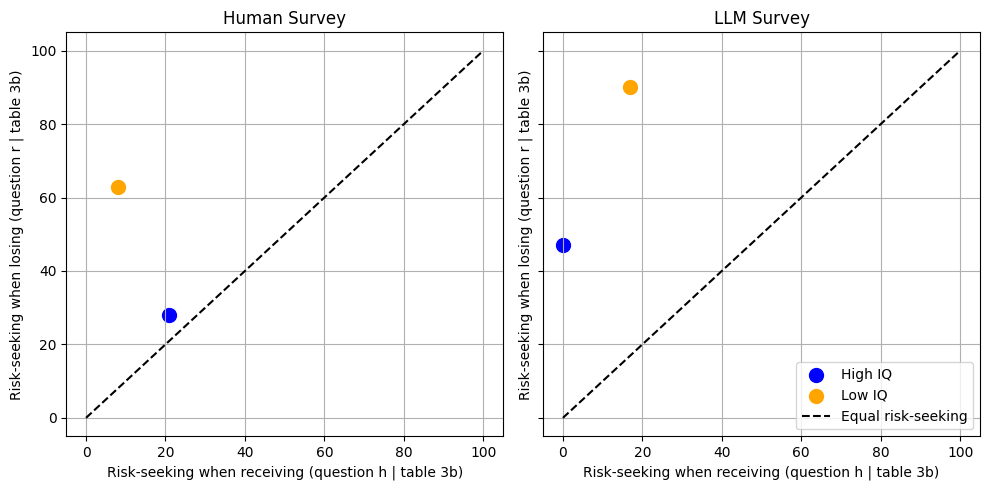

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Data points
# Left subplot (Human Survey)
human_high_iq = (21, 28)
human_low_iq = (8, 63)

# Right subplot (LLM Survey)
llm_high_iq = (0, 47)
llm_low_iq = (17, 90)

# Create figure and subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

# Function to plot scatter and bisector
def plot_scatter(ax, high_iq, low_iq, title, show_legend=True):
    ax.scatter(*high_iq, color='blue', label="High IQ", s=100)
    ax.scatter(*low_iq, color='orange', label="Low IQ", s=100)

    # Bisector (y = x)
    x = np.linspace(0, 100, 100)
    ax.plot(x, x, 'k--', label="Equal risk-seeking")

    # Labels, title, and grid
    ax.set_xlabel("Risk-seeking when receiving (question h | table 3b)")
    ax.set_ylabel("Risk-seeking when losing (question r | table 3b)")
    ax.set_title(title)
    ax.grid(True)

    # Show legend only if specified
    if show_legend:
        ax.legend()

# Plot Human Survey (no legend)
plot_scatter(axes[0], human_high_iq, human_low_iq, "Human Survey", show_legend=False)

# Plot LLM Survey (with legend)
plot_scatter(axes[1], llm_high_iq, llm_low_iq, "LLM Survey", show_legend=True)

# Adjust layout and show plot
plt.tight_layout()
plt.show()


# Part 4) Robustness Check: Framing Effect
In this section, I investigate the presence of the framing effect in large language models. Specifically, I examine whether the way questions are framed or presented together influences the LLM's responses. The results show that the LLM does not exhibit a framing effect, meaning its responses remain consistent regardless of how the questions are framed or grouped. However, this lack of effect contrasts with human behavior, where framing can significantly impact responses in surveys. This finding highlights the potential for future research to explore how framing might influence human participants in similar contexts.

In [17]:
q_3a_a = QuestionYesNo(
    question_name="table_3a_question_a",
    question_text="Do you prefer a 90% chance of $5,000 over $1,000 for sure?"
)

q_3a_b = QuestionYesNo(
    question_name="table_3a_question_b",
    question_text="Do you prefer a 90% chance of $500 over $100 for sure?"
)

q_3a_c = QuestionYesNo(
    question_name="table_3a_question_c",
    question_text="Do you prefer a 75% chance of $4,000 over $1,000 for sure?"
)

q_3a_d = QuestionYesNo(
    question_name="table_3a_question_d",
    question_text="Do you prefer a 75% chance of $200 over $100 for sure?"
)

q_3a_e = QuestionYesNo(
    question_name="table_3a_question_e",
    question_text="Do you prefer a 75% chance of $150 over $100 for sure?"
)

q_3a_f = QuestionYesNo(
    question_name="table_3a_question_f",
    question_text="Do you prefer a 50% chance of $300 over $100 for sure?"
)

q_3a_g = QuestionYesNo(
    question_name="table_3a_question_g",
    question_text="Do you prefer a 15% chance of $1,000,000 over $500 for sure?"
)

q_3a_h = QuestionYesNo(
    question_name="table_3a_question_h",
    question_text="Do you prefer a 3% chance of $7,000 over $100 for sure?"
)

q_3a_i = QuestionYesNo(
    question_name="table_3a_question_i",
    question_text="Do you prefer a 25% chance of $200 over $100 for sure?"
)

q_3a_j = QuestionYesNo(
    question_name="table_3a_question_j",
    question_text="Do you prefer a 25% chance of $300 over $100 for sure?"
)

q_3a_k = QuestionYesNo(
    question_name="table_3a_question_k",
    question_text="Do you prefer a 4% chance of $80 over $5 for sure?"
)

q_3a_l = QuestionYesNo(
    question_name="table_3a_question_l",
    question_text="Do you prefer a 1% chance of $80 over $5 for sure?"
)

q_3a_m = QuestionYesNo(
    question_name="table_3a_question_m",
    question_text="Do you prefer a 1% chance of $5,000 over $60 for sure?"
)

q_3a_n = QuestionYesNo(
    question_name="table_3a_question_n",
    question_text="Do you prefer a 90% chance to lose $50 over losing $10 for sure?"
)

q_3a_o = QuestionYesNo(
    question_name="table_3a_question_o",
    question_text="Do you prefer a 75% chance to lose $200 over losing $100 for sure?"
)

q_3a_p = QuestionYesNo(
    question_name="table_3a_question_p",
    question_text="Do you prefer a 50% chance to lose $300 over losing $100 for sure?"
)

q_3a_q = QuestionYesNo(
    question_name="table_3a_question_q",
    question_text="Do you prefer a 10% chance to lose $800 over losing $50 for sure?"
)

q_3a_r = QuestionYesNo(
    question_name="table_3a_question_r",
    question_text="Do you prefer a 3% chance to lose $7,000 over losing $100 for sure?"
)


In [18]:
survey = Survey([q_3a_a, q_3a_b, q_3a_c, q_3a_d, q_3a_e, q_3a_f, q_3a_g, q_3a_h, q_3a_i, q_3a_j, q_3a_k,
    q_3a_l, q_3a_m, q_3a_n, q_3a_o, q_3a_p, q_3a_q, q_3a_r])

In [19]:
results_part3 = survey.by(agents).run(remote_inference_description = "Human-like experiment")

Job UUID,38a1ef77-4c5a-4646-8ca0-19ff20fe4fc7
Progress Bar URL,https://www.expectedparrot.com/home/remote-job-progress/38a1ef77-4c5a-4646-8ca0-19ff20fe4fc7
Exceptions Report URL,None
Results UUID,3244466c-f7a3-41b9-8068-f8c1a42a77a4
Results URL,https://www.expectedparrot.com/content/3244466c-f7a3-41b9-8068-f8c1a42a77a4


## Data Cleaing

In [20]:
# convert results to dataframe
import pandas as pd
res = results_part3.select("answer_correctly", "answer.*")
merged_res = {k: v for d in res for k, v in d.items()}
df = pd.DataFrame(merged_res)
df

# Convert 'Yes' to 1.0 and 'No' to 0.0
for column in df.columns:
    if column.startswith('answer.table'):
        df[column] = df[column].map({'Yes': 1.0, 'No': 0.0})
# rename iq column
df["agent.answer_correctly"] = df["agent.answer_correctly"].map(
    {"You are dumb and sometimes answer incorrectly.": "Low",
     "You are smart and have the ability to answer correctly.": "High"})

In [21]:
# Group by IQ level
grouped_df = df.groupby("agent.answer_correctly").mean().T

# Rename columns in the DataFrame
column_rename_map = {
    'answer.table_3a_question_a': 'a. $1,000 for sure or a 90% chance of $5,000',
    'answer.table_3a_question_b': 'b. $100 for sure or a 90% chance of $500',
    'answer.table_3a_question_c': 'c. $1,000 for sure or a 75% chance of $4,000',
    'answer.table_3a_question_d': 'd. $100 for sure or a 75% chance of $200',
    'answer.table_3a_question_e': 'e. $100 for sure or a 75% chance of $150',
    'answer.table_3a_question_f': 'f. $100 for sure or a 50% chance of $300',
    'answer.table_3a_question_g': 'g. $500 for sure or a 15% chance of $1,000,000',
    'answer.table_3a_question_h': 'h. $100 for sure or a 3% chance of $7,000',
    'answer.table_3a_question_i': 'i. $100 for sure or a 25% chance of $200',
    'answer.table_3a_question_j': 'j. $100 for sure or a 25% chance of $300',
    'answer.table_3a_question_k': 'k. $5 for sure or a 4% chance of $80',
    'answer.table_3a_question_l': 'l. $5 for sure or a 1% chance of $80',
    'answer.table_3a_question_m': 'm. $60 for sure or a 1% chance of $5000',
    'answer.table_3a_question_n': 'n. Lose $10 for sure or a 90% chance to lose $50',
    'answer.table_3a_question_o': 'o. Lose $100 for sure or a 75% chance to lose $200',
    'answer.table_3a_question_p': 'p. Lose $100 for sure or a 50% chance to lose $300',
    'answer.table_3a_question_q': 'q. Lose $50 for sure or a 10% chance to lose $800',
    'answer.table_3a_question_r': 'r. Lose $100 for sure or a 3% chance to lose $7,000'
}
grouped_df.rename(index=column_rename_map, inplace=True)

# Table3b of paper
grouped_df = grouped_df.sort_index()

## No framing effect in Table 3a
The results show that the LLM does not exhibit a framing effect, meaning its responses remain consistent regardless of how the questions are framed or grouped.

In [22]:
grouped_df

agent.answer_correctly,High,Low
"a. $1,000 for sure or a 90% chance of $5,000",0.960630,0.525581
b. $100 for sure or a 90% chance of $500,0.952756,0.962791
"c. $1,000 for sure or a 75% chance of $4,000",0.275591,0.716279
d. $100 for sure or a 75% chance of $200,0.590551,0.679070
e. $100 for sure or a 75% chance of $150,0.582677,0.944186
f. $100 for sure or a 50% chance of $300,0.125984,0.176744
"g. $500 for sure or a 15% chance of $1,000,000",0.000000,0.818605
"h. $100 for sure or a 3% chance of $7,000",0.000000,0.176744
i. $100 for sure or a 25% chance of $200,0.070866,0.590698
j. $100 for sure or a 25% chance of $300,0.070866,0.218605


# References
- Frederick, Shane. "Cognitive reflection and decision making." Journal of Economic perspectives 19, no. 4 (2005): 25-42.
- Enke, Benjamin, Thomas Graeber, Ryan Oprea, and Jeffrey Yang. Behavioral attenuation. No. w32973. National Bureau of Economic Research, 2024.

---
